<a href="https://www.kaggle.com/code/shaimamamoun/malaria-mobilenetv2-training?scriptVersionId=367837100" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

**Development Environment Setup**

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
from tensorflow.keras.applications import MobileNetV2
print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


**Data Preparation**

**Dataset Characteristics**

In [2]:
import os
base_dir = '/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/cell_images'
valid_ext = (".png", ".jpg", ".jpeg")
for folder in os.listdir(base_dir):
    path = os.path.join(base_dir, folder)
    count = len([f for f in os.listdir(path) if f.lower().endswith(valid_ext)])
    print(f"{folder}: {count} images")

Parasitized: 13779 images
Uninfected: 13779 images


In [3]:
for c in os.listdir(base_dir):
    p = os.path.join(base_dir, c)
    print(c, [f for f in os.listdir(p) if not f.lower().endswith((".png", ".jpg", ".jpeg"))])

Parasitized ['Thumbs.db']
Uninfected ['Thumbs.db']


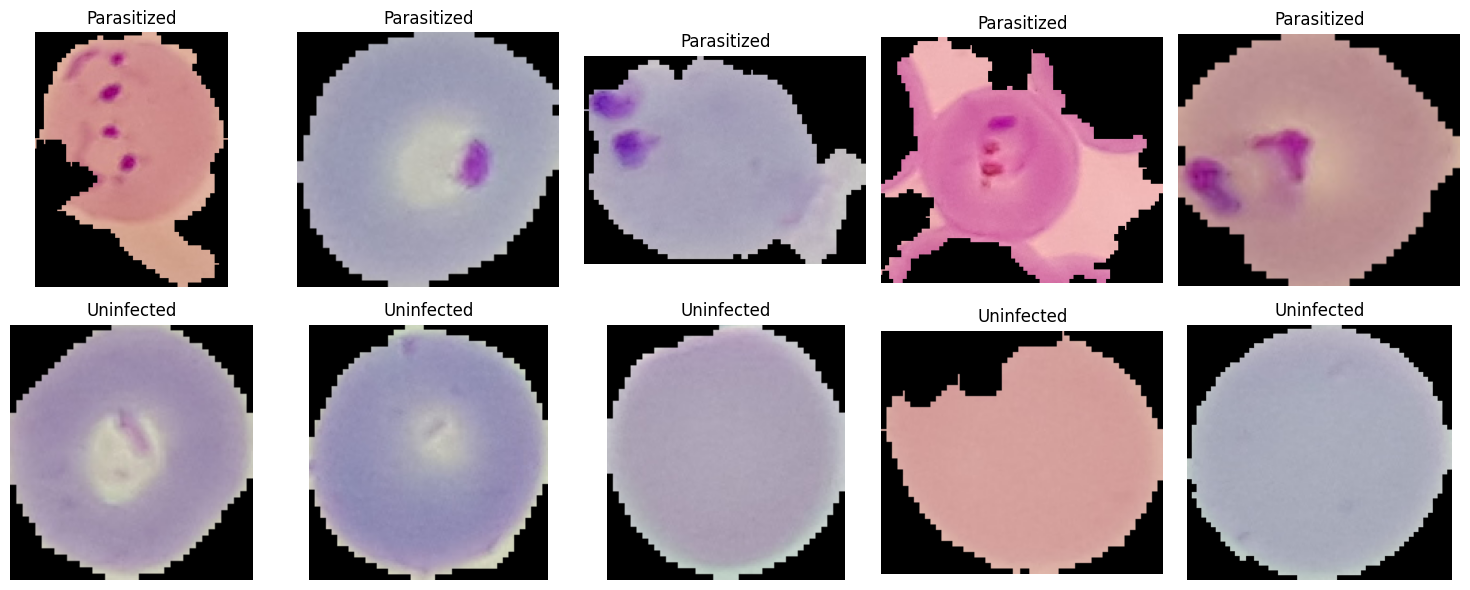

In [4]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, category in enumerate(['Parasitized', 'Uninfected']):
    folder = os.path.join(base_dir, category)
    images = random.sample(os.listdir(folder), 5)
    for j, img_name in enumerate(images):
        img = mpimg.imread(os.path.join(folder, img_name))
        axes[i][j].imshow(img)
        axes[i][j].set_title(category)
        axes[i][j].axis('off')
plt.tight_layout()
plt.show()

**Train/Validation/Test Split**

In [5]:
!pip install split-folders -q
import splitfolders

IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42

# Physically split into train/val/test folders (80/10/10)
splitfolders.ratio(
    base_dir,
    output="/kaggle/working/split_data",
    seed=SEED,
    ratio=(.8, .1, .1)
)

train_dir = "/kaggle/working/split_data/train"
val_dir   = "/kaggle/working/split_data/val"
test_dir  = "/kaggle/working/split_data/test"

# Confirm the split worked
for split in ["train", "val", "test"]:
    for cls in ["Parasitized", "Uninfected"]:
        p = os.path.join("/kaggle/working/split_data", split, cls)
        print(split, cls, len(os.listdir(p)))


Copying files: 27560 files [38:03, 12.07 files/s]

train Parasitized 11024
train Uninfected 11024
val Parasitized 1378
val Uninfected 1378
test Parasitized 1378
test Uninfected 1378


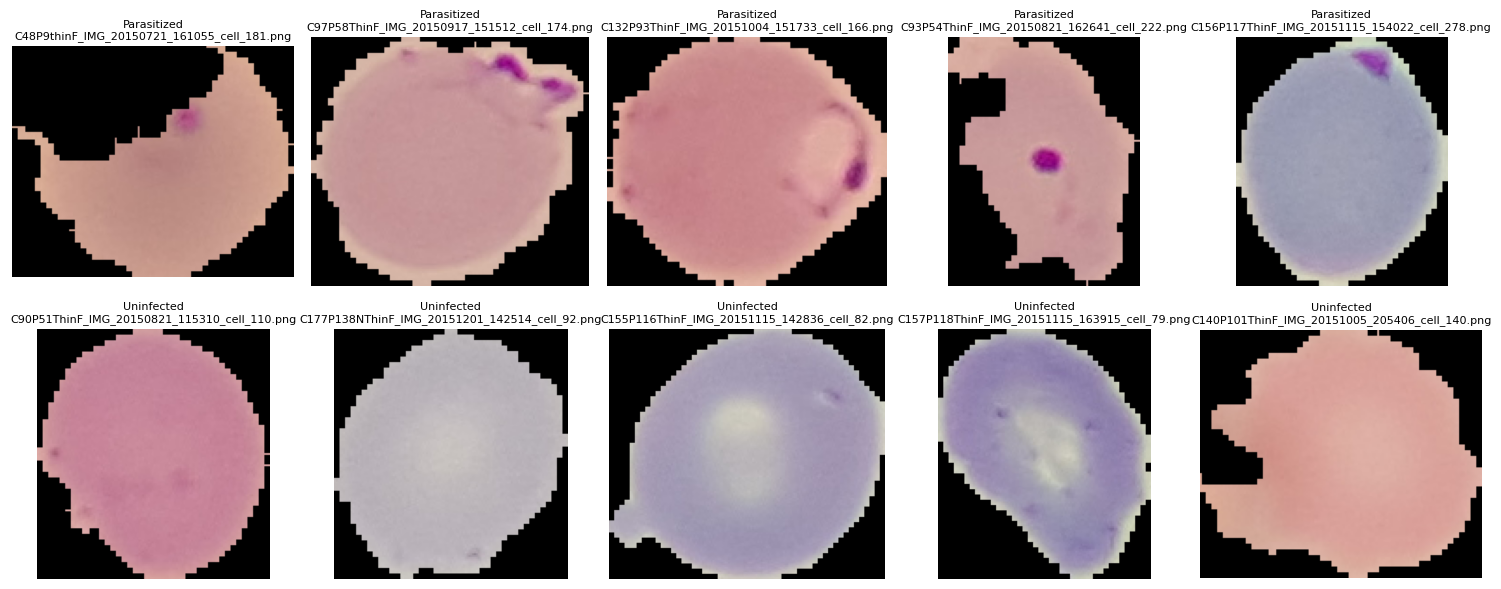

In [6]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os, random

test_dir = "/kaggle/working/split_data/test"

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, category in enumerate(['Parasitized', 'Uninfected']):
    folder = os.path.join(test_dir, category)
    images = random.sample(os.listdir(folder), 5)
    for j, img_name in enumerate(images):
        img = mpimg.imread(os.path.join(folder, img_name))
        axes[i][j].imshow(img)
        axes[i][j].set_title(f"{category}\n{img_name}", fontsize=8)
        axes[i][j].axis('off')

plt.tight_layout()
plt.show()

**Data Generators and Augmentation**

In [7]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
# Training generator — WITH augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.2,
    brightness_range=[0.8, 1.2]
)

# Validation and test generators — NO augmentation, only normalisation
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir, target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    class_mode='binary', seed=SEED
)

val_generator = val_datagen.flow_from_directory(
    val_dir, target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    class_mode='binary', seed=SEED
)

print("Training samples:", train_generator.samples)
print("Validation samples:", val_generator.samples)
print("Classes:", train_generator.class_indices)


Found 22046 images belonging to 2 classes.
Found 2756 images belonging to 2 classes.
Training samples: 22046
Validation samples: 2756
Classes: {'Parasitized': 0, 'Uninfected': 1}


 **Model Development**

**Base Model and Classification Head**

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models, Model


base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,       
    weights='imagenet'       
)


base_model.trainable = False

print("Base model layers:", len(base_model.layers))
print("Trainable layers:", sum([l.trainable for l in base_model.layers]))

In [ ]:

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)    
x = layers.Dense(128, activation='relu')(x) 
x = layers.Dropout(0.3)(x)                
outputs = layers.Dense(1, activation='sigmoid')(x)  

model = Model(inputs, outputs)
model.summary()

**Feature Extraction Phase**

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall'),
             tf.keras.metrics.AUC(name='auc')]
)


callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '/kaggle/working/best_model_phase1.keras',
        save_best_only=True,
        monitor='val_accuracy',
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=5,          
        restore_best_weights=True,
        verbose=1
    )
]

EPOCHS_PHASE1 = 10

history_phase1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_PHASE1,
    callbacks=callbacks,
    verbose=1
)

In [ ]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    # Accuracy
    axes[0].plot(history.history['accuracy'], label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Validation')
    axes[0].set_title(f'{title} — Accuracy')
    axes[0].legend()
    # Loss
    axes[1].plot(history.history['loss'], label='Train')
    axes[1].plot(history.history['val_loss'], label='Validation')
    axes[1].set_title(f'{title} — Loss')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(history_phase1, "Phase 1: Feature Extraction")

**Fine-Tuning Phase**

In [ ]:

base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False


model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), 
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall'),
             tf.keras.metrics.AUC(name='auc')]
)

callbacks_ft = [
    tf.keras.callbacks.ModelCheckpoint(
        '/kaggle/working/best_model_finetuned.keras',
        save_best_only=True,
        monitor='val_accuracy',
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=7,
        restore_best_weights=True,
        verbose=1
    )
]

EPOCHS_PHASE2 = 15

history_phase2 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_PHASE2,
    callbacks=callbacks_ft,
    verbose=1
)

plot_history(history_phase2, "Phase 2: Fine-tuning")

In [ ]:
model.save('/kaggle/working/malaria_mobilenetv2_final.keras')
print("Model saved.")

**This step for loading the model when starting new session**

In [9]:
import tensorflow as tf 
model = tf.keras.models.load_model('/kaggle/input/models/shaimamamoun/malaria-mobilenetv2-final/keras/default/1/malaria_mobilenetv2_final.keras')

I0000 00:00:1794257014.264184      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1794257014.271933      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


**Model Evaluation**

**Generating Predictions**

In [10]:
test_generator = test_datagen.flow_from_directory(
    test_dir, target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    class_mode='binary', shuffle=False
)



Found 2756 images belonging to 2 classes.


In [11]:
import numpy as np
y_pred_prob = model.predict(test_generator, verbose=1)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()
y_true = test_generator.classes

2026-11-09 20:44:13.537144: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 20:44:13.674025: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1794257055.381870     175 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


86/87 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step

2026-11-09 20:44:28.010414: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 20:44:28.147607: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


87/87 ━━━━━━━━━━━━━━━━━━━━ 31s 165ms/step


**Classification Report**

In [28]:
import pandas as pd
from IPython.display import display
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

auc = roc_auc_score(y_true, y_pred_prob)
cm = confusion_matrix(y_true, y_pred)   

rows = []
for idx, name in [(0, "Parasitized (infected)"), (1, "Uninfected (healthy)")]:
    rows.append({
        "Class": name,
        "Images tested": f"{cm[idx].sum():,}",
        "Correctly identified": f"{cm[idx, idx]:,}",
        "Recall": f"{recall_score(y_true, y_pred, pos_label=idx):.1%}",
        "Precision": f"{precision_score(y_true, y_pred, pos_label=idx):.1%}",
        "F1-score": f"{f1_score(y_true, y_pred, pos_label=idx):.1%}",
    })
table_classes = pd.DataFrame(rows).set_index("Class")

table_overall = pd.DataFrame(
    {"Result": [
        f"{accuracy_score(y_true, y_pred):.1%} ({cm.trace():,} of {cm.sum():,} images correct)",
        f"{auc:.3f}",
    ]},
    index=["Accuracy", "AUC"],
)
table_overall.index.name = "Overall measure"

display(table_classes)
display(table_overall)


,Images tested,Correctly identified,Recall,Precision,F1-score
Class,,,,,
Parasitized (infected),"1,378","1,303",94.6%,97.7%,96.1%
Uninfected (healthy),"1,378","1,348",97.8%,94.7%,96.3%


,Result
Overall measure,
Accuracy,"96.2% (2,651 of 2,756 images correct)"
AUC,0.992


**Confusion Matrix**

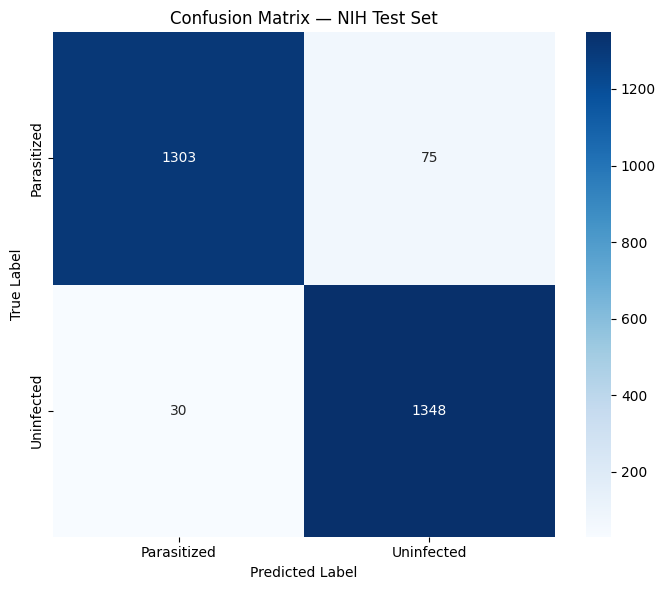

In [16]:
import seaborn as sns
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Parasitized", "Uninfected"],  
    yticklabels=["Parasitized", "Uninfected"])  
plt.title("Confusion Matrix — NIH Test Set")
plt.ylabel("True Label"); plt.xlabel("Predicted Label")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()


**ROC Curve and AUC**

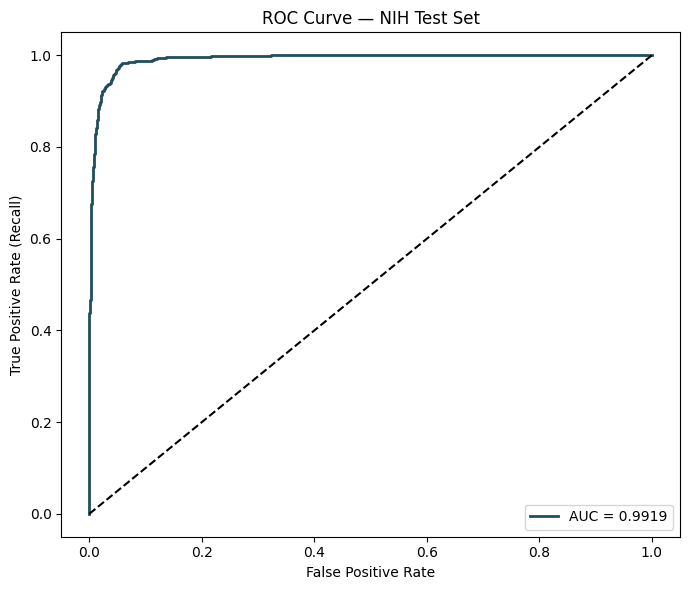

In [17]:
fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}", color="#1F4E5C", linewidth=2)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — NIH Test Set")
plt.legend()
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=150)
plt.show()

**Explainability (Grad-CAM and Grad-CAM++)**

In [18]:
!pip install tf-keras-vis -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.5/52.5 kB 1.2 MB/s eta 0:00:00a 0:00:01


**Locating the Target Convolutional Layer**

In [19]:
last_conv_layer = None
for layer in reversed(model.layers):
    try:
        if len(layer.output_shape) == 4:
            last_conv_layer = layer.name
            break
    except AttributeError:
        continue
print("Last conv layer:", last_conv_layer)

Last conv layer: mobilenetv2_1.00_224


**Grad-CAM functions**


In [20]:
def overlay_heatmap(img_path, heatmap, alpha=0.4):
    img = keras_image.load_img(img_path, target_size=(224, 224))
    img_arr = keras_image.img_to_array(img)
    jet_colors = plt.cm.jet(np.arange(256))[:, :3]
    jet_hm = keras_image.array_to_img(jet_colors[np.uint8(255 * heatmap)])
    jet_hm = jet_hm.resize((224, 224))
    jet_hm = keras_image.img_to_array(jet_hm)
    return keras_image.array_to_img(jet_hm * alpha + img_arr)

In [21]:
def get_gradcam_heatmap(model, img_array, last_conv_layer_name):
    base_model = model.get_layer(last_conv_layer_name)
    idx = model.layers.index(base_model)
    classifier_layers = model.layers[idx + 1:]

    with tf.GradientTape() as tape:
        conv_outputs = base_model(img_array, training=False)
        tape.watch(conv_outputs)
        x = conv_outputs
        for layer in classifier_layers[:-1]:
            x = layer(x)
        final_layer = classifier_layers[-1]
        logit = tf.matmul(x, final_layer.kernel) + final_layer.bias
        prob = tf.sigmoid(logit)
        class_channel = tf.where(prob[:, 0] > 0.5, logit[:, 0], -logit[:, 0])

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = conv_outputs[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

**Grad-CAM++ Function**

In [22]:
def get_gradcam_pp_heatmap(model, img_array, last_conv_layer_name):
    base_model = model.get_layer(last_conv_layer_name)
    idx = model.layers.index(base_model)
    classifier_layers = model.layers[idx + 1:]

    with tf.GradientTape() as tape:
        conv_outputs = base_model(img_array, training=False)
        tape.watch(conv_outputs)
        x = conv_outputs
        for layer in classifier_layers[:-1]:
            x = layer(x)
        final_layer = classifier_layers[-1]
        logit = tf.matmul(x, final_layer.kernel) + final_layer.bias
        prob = tf.sigmoid(logit)
        class_channel = tf.where(prob[:, 0] > 0.5, logit[:, 0], -logit[:, 0])

    grads = tape.gradient(class_channel, conv_outputs)[0]
    conv_outputs = conv_outputs[0]

    grads_power_2 = grads ** 2
    grads_power_3 = grads ** 3
    global_sum = tf.reduce_sum(conv_outputs, axis=(0, 1))

    alpha_denom = grads_power_2 * 2.0 + global_sum * grads_power_3
    alpha_denom = tf.where(alpha_denom != 0.0, alpha_denom, tf.ones_like(alpha_denom))
    alphas = grads_power_2 / alpha_denom
    alphas_norm = alphas / (tf.reduce_sum(alphas, axis=(0, 1)) + 1e-8)

    weights = tf.reduce_sum(tf.nn.relu(grads) * alphas_norm, axis=(0, 1))

    heatmap = tf.reduce_sum(weights * conv_outputs, axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

**Side-by-side comparison Function**

In [24]:
def compare_gradcam_methods(img_path, model, last_conv_layer, true_label):
    img = keras_image.load_img(img_path, target_size=(224, 224))
    img_array = np.expand_dims(keras_image.img_to_array(img) / 255.0, axis=0)

    pred = model.predict(img_array, verbose=0)[0][0]
    pred_label = "Uninfected" if pred > 0.5 else "Parasitized"
    confidence = pred if pred > 0.5 else 1 - pred

    heatmap_v1 = get_gradcam_heatmap(model, img_array, last_conv_layer)
    heatmap_v2 = get_gradcam_pp_heatmap(model, img_array, last_conv_layer)
    overlay_v1 = overlay_heatmap(img_path, heatmap_v1)
    overlay_v2 = overlay_heatmap(img_path, heatmap_v2)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img)
    axes[0].set_title(f"Original\nTrue: {true_label}")
    axes[0].axis("off")
    axes[1].imshow(overlay_v1)
    axes[1].set_title(f"Grad-CAM\nPred: {pred_label} ({confidence:.1%})")
    axes[1].axis("off")
    axes[2].imshow(overlay_v2)
    axes[2].set_title(f"Grad-CAM++\nPred: {pred_label} ({confidence:.1%})")
    axes[2].axis("off")
    plt.tight_layout()
    plt.show()

**Find misclassified test images** 

In [25]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image as keras_image

In [26]:
p_dir = os.path.join(test_dir, "Parasitized")
u_dir = os.path.join(test_dir, "Uninfected")

wrong_examples = []
for label_name, folder in [("Parasitized", p_dir), ("Uninfected", u_dir)]:
    found = 0
    for nm in os.listdir(folder)[:300]:
        img_path = os.path.join(folder, nm)
        img = keras_image.load_img(img_path, target_size=(224, 224))
        arr = np.expand_dims(keras_image.img_to_array(img) / 255.0, axis=0)
        pred = model.predict(arr, verbose=0)[0][0]
        pred_label = "Uninfected" if pred > 0.5 else "Parasitized"
        if pred_label != label_name:
            wrong_examples.append((img_path, label_name))
            found += 1
            if found >= 2:
                break

print("Found", len(wrong_examples), "misclassified examples")
print(wrong_examples)

2026-11-09 20:46:53.233395: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 20:46:53.368056: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


Found 4 misclassified examples
[('/kaggle/working/split_data/test/Parasitized/C39P4thinF_original_IMG_20150622_113632_cell_1.png', 'Parasitized'), ('/kaggle/working/split_data/test/Parasitized/C116P77ThinF_IMG_20150930_171558_cell_93.png', 'Parasitized'), ('/kaggle/working/split_data/test/Uninfected/C37BP2_thinF_IMG_20150620_133001a_cell_68.png', 'Uninfected'), ('/kaggle/working/split_data/test/Uninfected/C216ThinF_IMG_20151106_135228_cell_220.png', 'Uninfected')]


**Run the comparison**

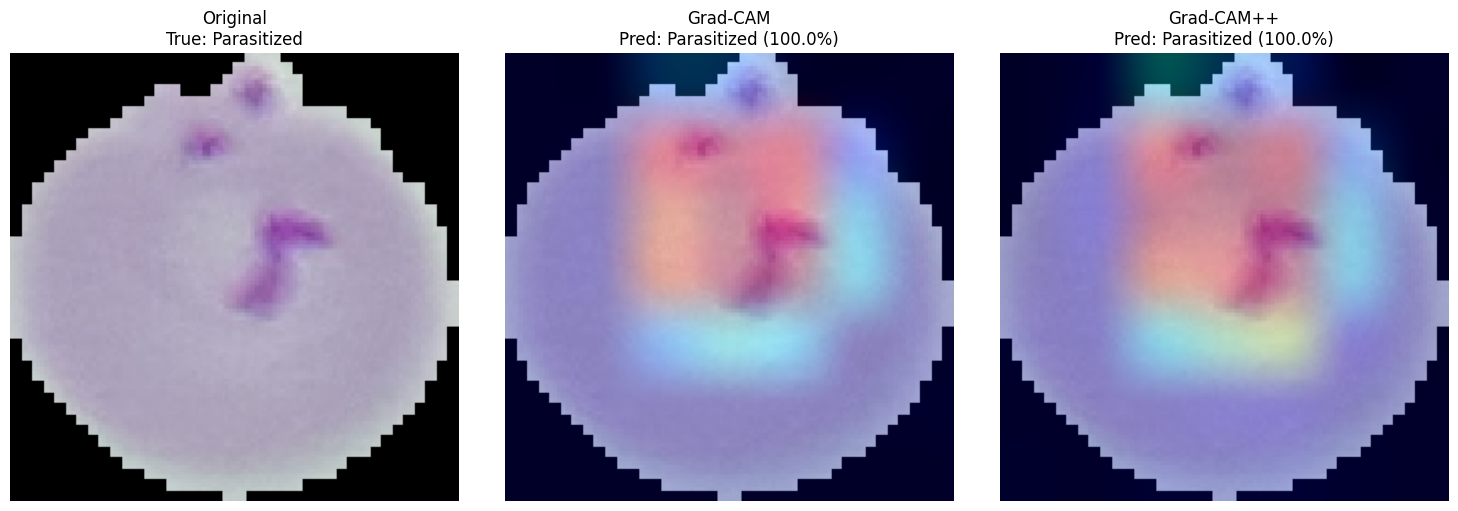

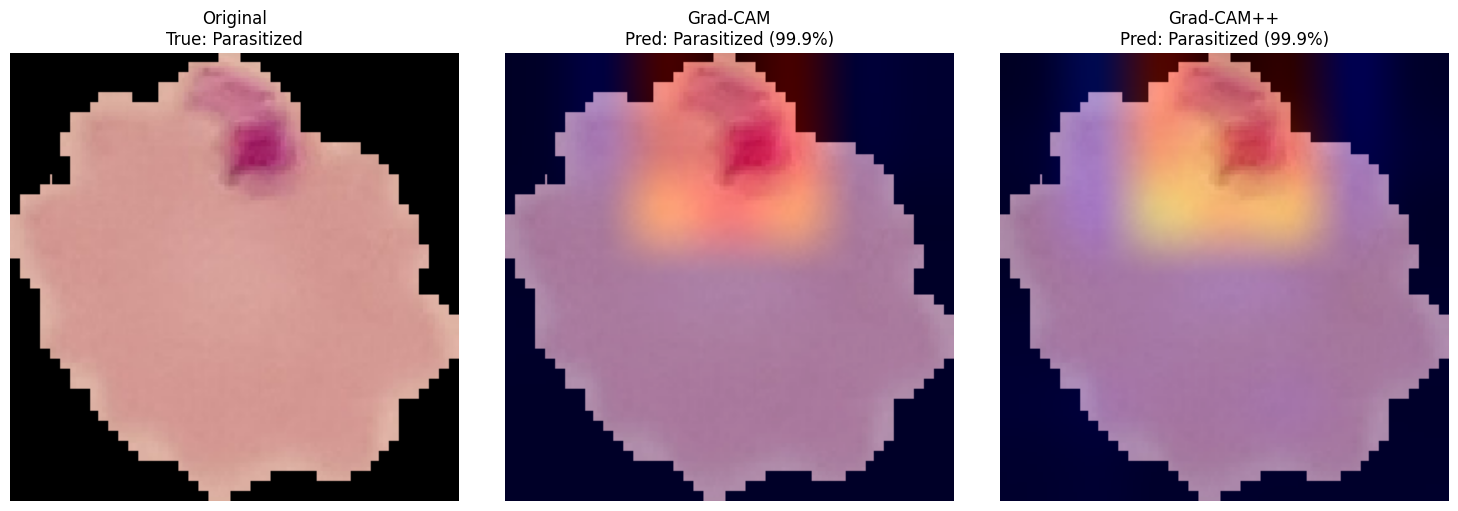

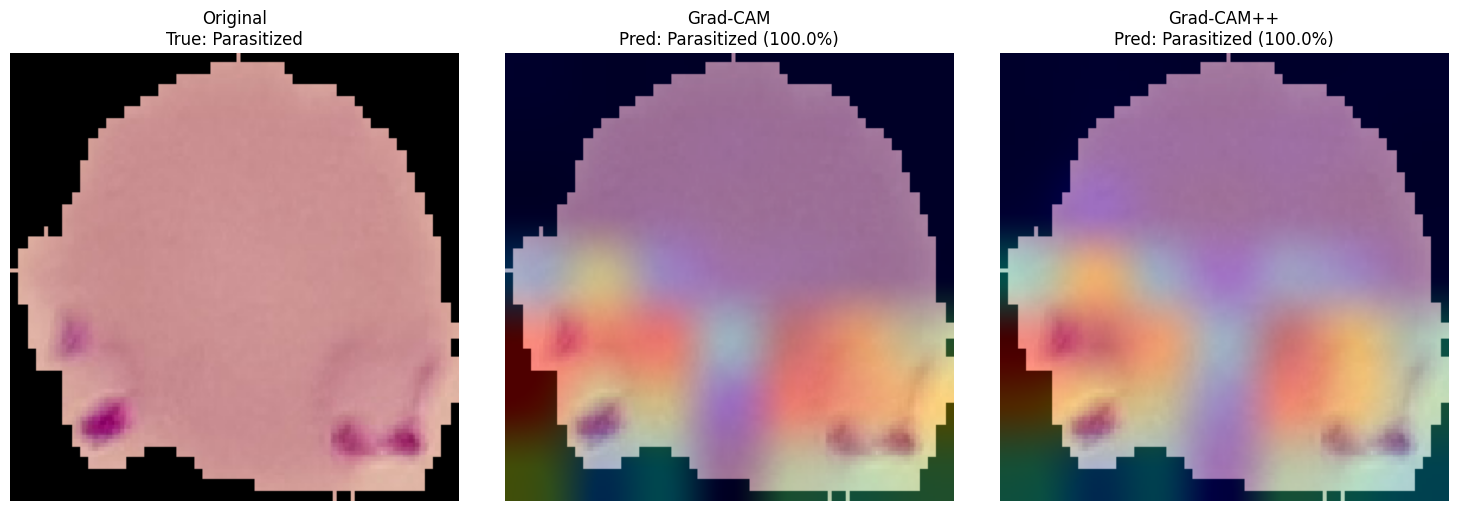

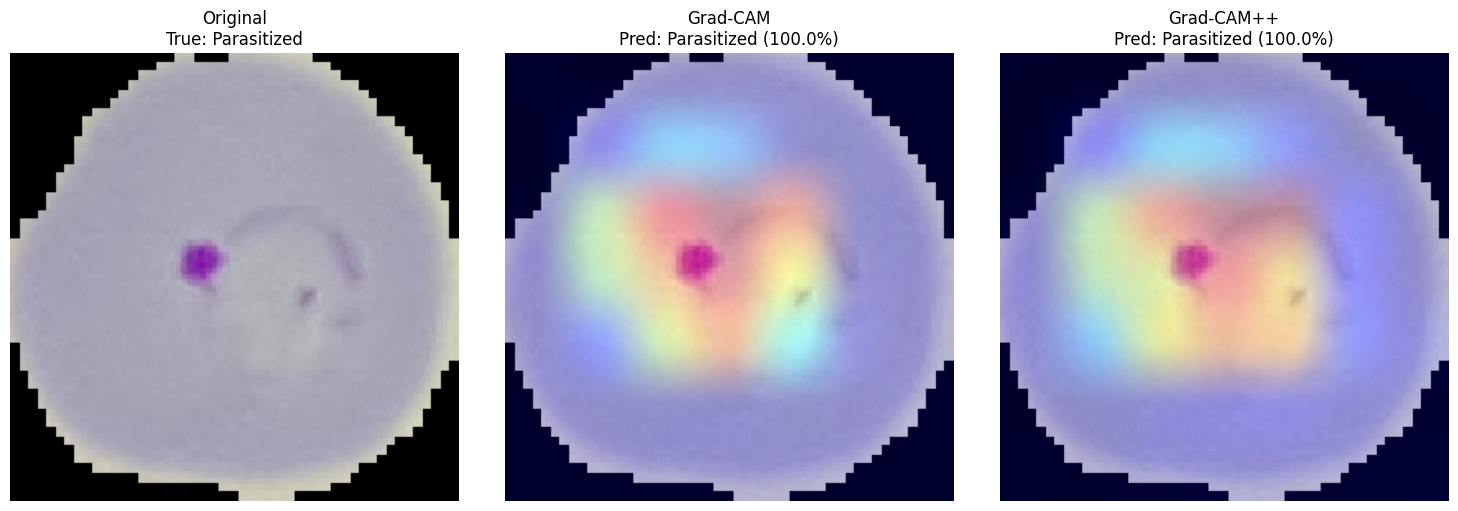

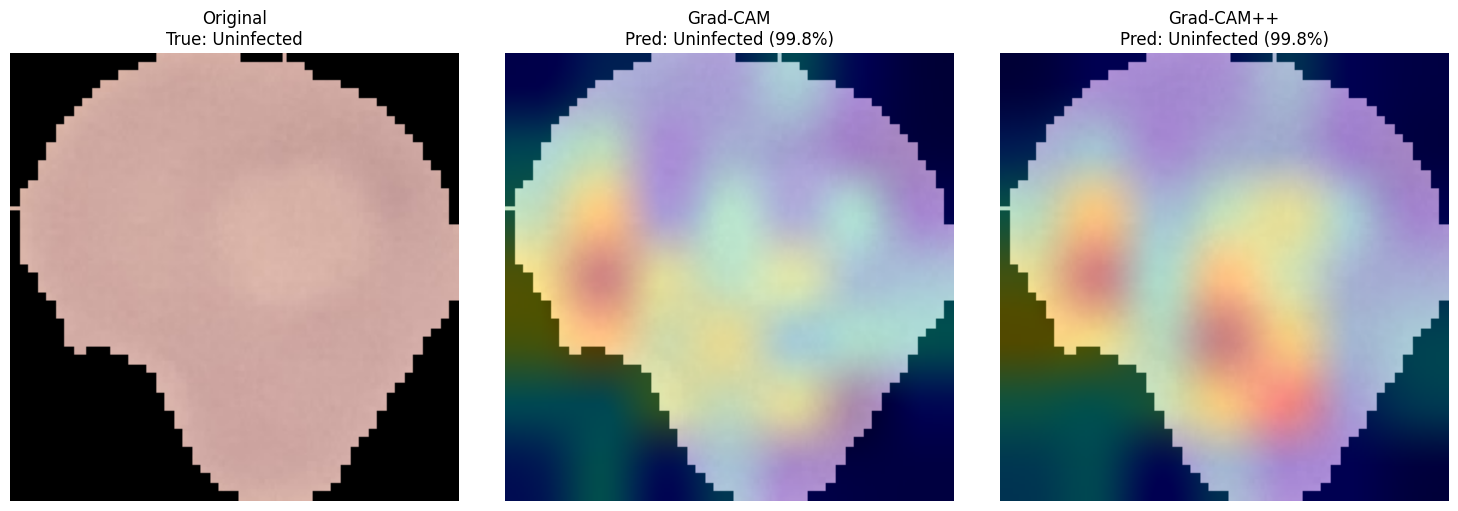

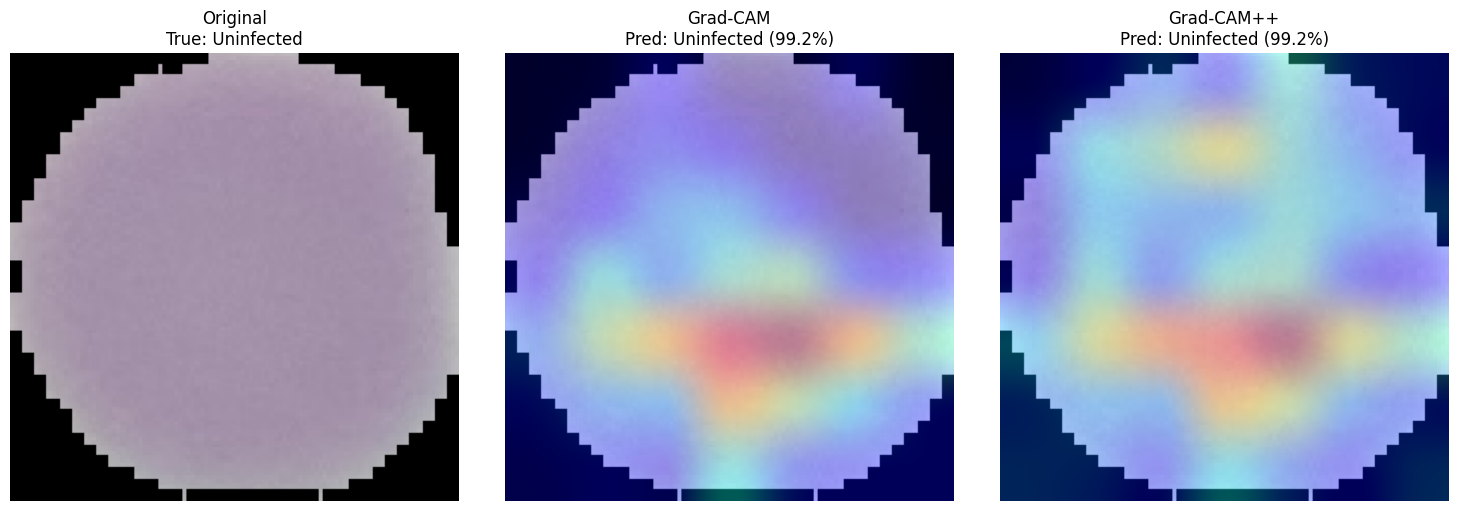

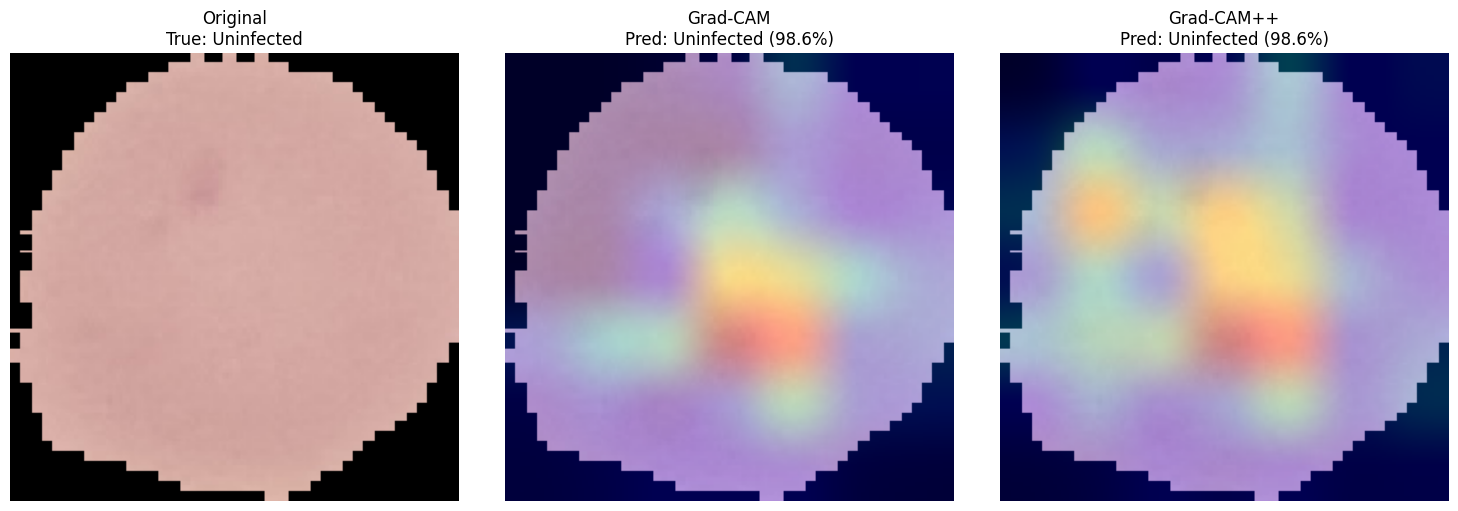

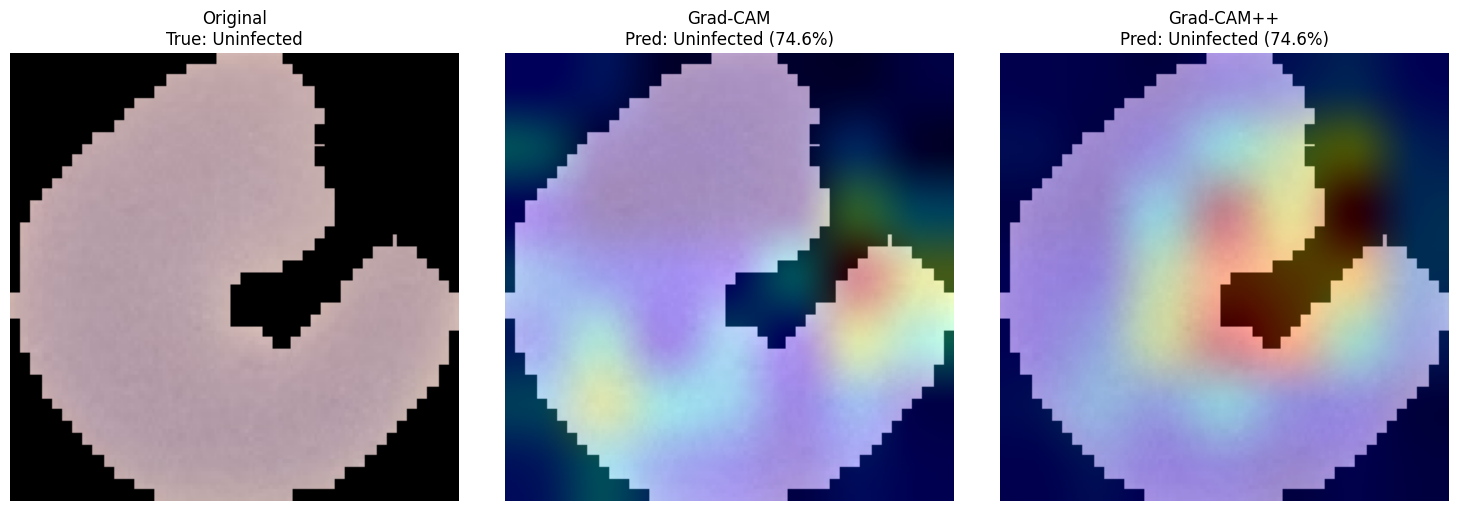

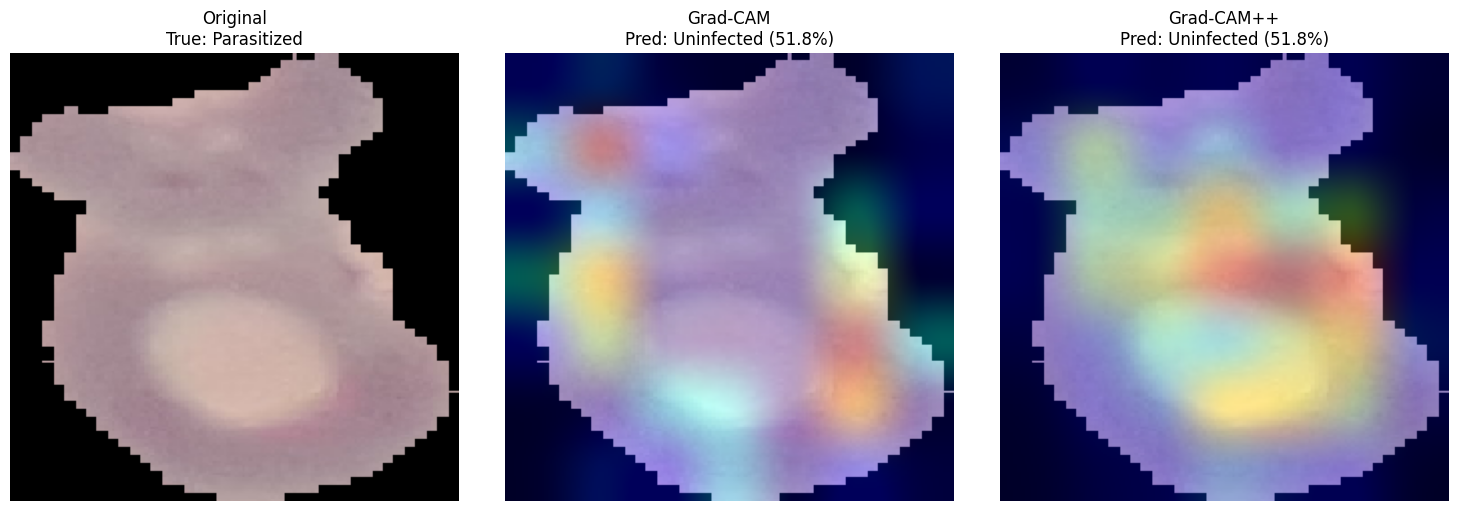

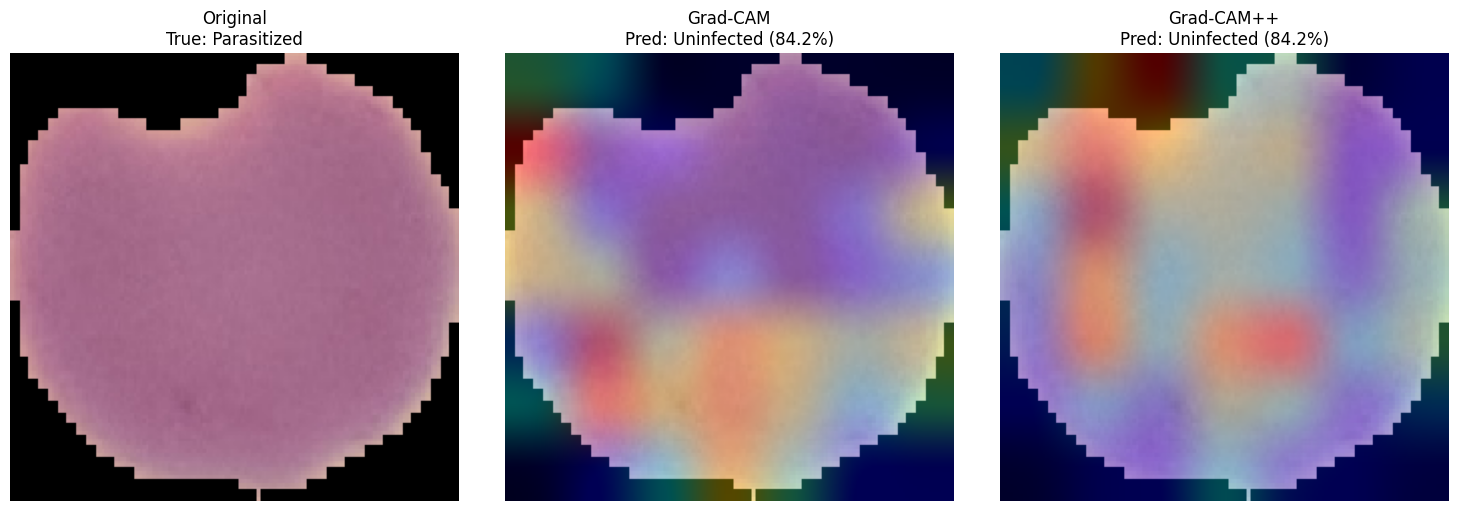

In [27]:
for nm in os.listdir(p_dir)[:4]:
    compare_gradcam_methods(os.path.join(p_dir, nm), model, last_conv_layer, "Parasitized")

for nm in os.listdir(u_dir)[:4]:
    compare_gradcam_methods(os.path.join(u_dir, nm), model, last_conv_layer, "Uninfected")

for img_path, true_label in wrong_examples[:2]:
    compare_gradcam_methods(img_path, model, last_conv_layer, true_label)